In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy.stats import poisson


In [3]:
rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "demand": rng.integers(50, 151, n),
    "supply": rng.integers(45, 141, n),
    "distance_km": rng.uniform(1, 15, n).round(1),
    "peak": rng.choice(
        ["Yes", "No"], n, p=[0.45, 0.55]
    ),
    "weather": rng.choice(
        ["Clear", "Rain"], n, p=[0.75, 0.25]
    )
})

noise = rng.normal(0, 1.7, n)

df["wait_min"] = (
    8
    + 0.12 * (df["demand"] - 100)
    - 0.09 * (df["supply"] - 90)
    + 0.25 * (df["distance_km"] - 7)
    + 1.5 * (df["peak"] == "Yes")
    + 2.0 * (df["weather"] == "Rain")
    + noise
).clip(lower=0.5).round(2)

# Binary target for Logistic Regression
df["late"] = (df["wait_min"] >= 10).astype(int)

display(df.head())
print(df.shape)
print(df["late"].value_counts())

,demand,supply,distance_km,peak,weather,wait_min,late
0,59,55,11.3,Yes,Clear,7.06,0
1,128,107,13.4,No,Rain,14.97,1
2,116,137,13.9,Yes,Clear,6.87,0
3,94,128,8.1,Yes,Clear,5.15,0
4,93,71,8.3,No,Rain,10.20,1


(500, 7)
late
0    290
1    210
Name: count, dtype: int64


late
0    290
1    210
Name: count, dtype: int64
late
0    0.58
1    0.42
Name: proportion, dtype: float64


<Axes: xlabel='late'>

Text(0.5, 0, 'Late Trip (0 = No, 1 = Yes)')

Text(0, 0.5, 'Count')

Text(0.5, 1.0, 'Distribution of Late Trips')

(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

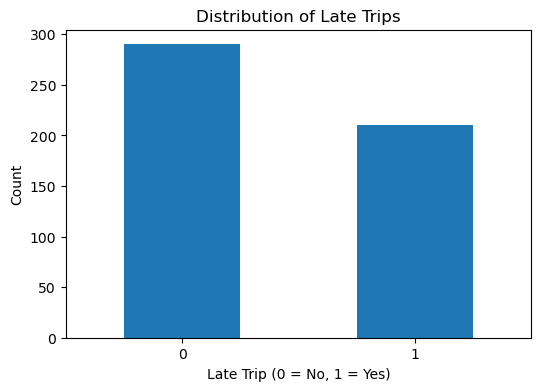

In [4]:
# Task 1. Calculate the number and proportion of late trips.

print(df["late"].value_counts())

print(
    df["late"].value_counts(normalize=True)
)

df["late"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.xlabel("Late Trip (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.title("Distribution of Late Trips")
plt.xticks(rotation=0)
plt.show()

In [11]:
# Task 2. Fit a logistic regression model to estimate the probability of a late trip.

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df[
    ["demand", "supply", "distance_km",
     "peak", "weather"]
]

y = df["late"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

preprocess = ColumnTransformer([
    ("num", StandardScaler(),
     ["demand", "supply", "distance_km"]),

    ("cat", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), ["peak", "weather"])
])

clf = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000))
])

clf.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['demand', 'supply',
                                                   'distance_km']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['peak', 'weather'])])),
                ('model', LogisticRegression(max_iter=1000))])

In [12]:
# Task 3. Calculate the predicted probability of lateness.

y_prob = clf.predict_proba(X_test)[:, 1]

y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Probability": y_prob,
    "Predicted": y_pred
})

display(results.head(10))

,Actual,Probability,Predicted
0,0,0.003896,0
1,1,0.986026,1
2,0,0.178451,0
3,0,0.623892,1
4,0,0.222117,0
5,0,0.218342,0
6,0,0.026540,0
7,1,0.907574,1
8,1,0.997558,1
9,1,0.990542,1


[[66  7]
 [11 41]]


Text(0.5, 1.0, 'Logistic Regression Confusion Matrix')

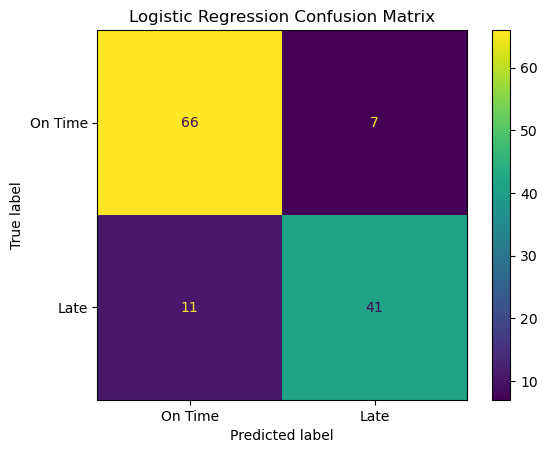

In [13]:
# Task 4. Create a confusion matrix.

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score
)

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["On Time", "Late"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [14]:
# Task 5. Calculate classification metrics.

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

Accuracy: 0.856
Precision: 0.8541666666666666
Recall: 0.7884615384615384


In [15]:
# Task 6. Compare thresholds of 0.3, 0.5, and 0.7.

for threshold in [0.3, 0.5, 0.7]:

    pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print(
        "Precision:",
        round(precision_score(y_test, pred), 3)
    )

    print(
        "Recall:",
        round(recall_score(y_test, pred), 3)
    )


Threshold: 0.3
Precision: 0.814
Recall: 0.923

Threshold: 0.5
Precision: 0.854
Recall: 0.788

Threshold: 0.7
Precision: 0.946
Recall: 0.673


ROC AUC: 0.9488935721812434


Text(0.5, 1.0, 'ROC Curve — Logistic Regression')

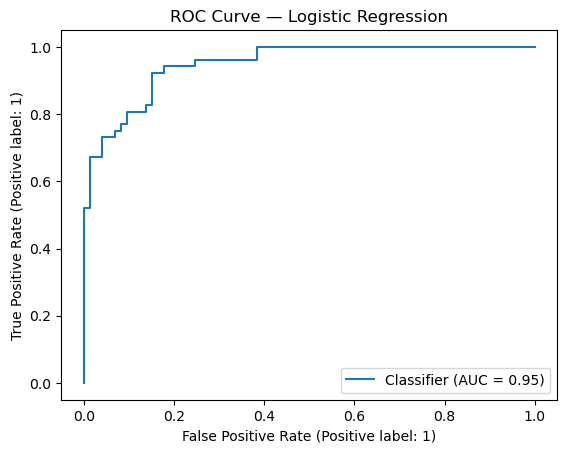

In [16]:
# Task 7. Draw the ROC curve and calculate ROC AUC.

from sklearn.metrics import (
    roc_auc_score,
    RocCurveDisplay
)

auc = roc_auc_score(y_test, y_prob)

print("ROC AUC:", auc)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("ROC Curve — Logistic Regression")
plt.show()

In [17]:
# Task 8. Predict the lateness probability for a new ride request.

new_trip = pd.DataFrame({
    "demand": [125],
    "supply": [65],
    "distance_km": [8.0],
    "peak": ["Yes"],
    "weather": ["Rain"]
})

probability = clf.predict_proba(new_trip)[0, 1]

print(
    "P(Late):",
    round(probability, 3)
)

print(
    "Prediction:",
    "Late" if probability >= 0.5 else "On Time"
)

P(Late): 0.996
Prediction: Late
